¡Hola Yaritza! Espero estés bien.

Mi nombre es **Gina Buvoli**. Un gusto conocerte, seré tu revisora en este proyecto.

A continuación, te comparto un poco sobre la modalidad de revisión que vamos a usar:

Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para mejorar tu código, así como comentarios sobre tus conclusiones o percepciones sobre el tema.

Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más precisa, junto con algunos ejemplos prácticos. También estoy abierta a responder cualquier duda que tengas.

Encontrarás mis comentarios a continuación: por favor, no los muevas, modifiques ni elimines.

---

### Formato de Comentarios

Revisaré cuidadosamente cada implementación en tu notebook para asegurar que cumpla con los requisitos y te daré comentarios de acuerdo al siguiente formato:

<div class="alert alert-block alert-success">
<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>
¡Excelente trabajo! Esta parte está bien implementada y contribuye significativamente al análisis. Continúa aplicando estas buenas prácticas en futuras secciones.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>
<b>Atención ⚠️</b><br>
El código es correcto, pero hay una recomendación de mejora. No bloquea la aprobación, pero vale la pena ajustarlo.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>
Aquí hay un error que es necesario corregir para aprobar. Por favor revisa este punto antes de volver a enviar.
</div>

---

En cada revisión recibirás un **Comentario General** que resume los aspectos positivos, las áreas de mejora y los próximos pasos.

También puedes responderme copiando el siguiente bloque si tienes alguna duda:

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante [#° iteración]</b> <a class="tocSkip"></a>

Aquí puedes escribir tu respuesta o pregunta.
</div>

**¡Empecemos!** 🚀

<div class="alert alert-block alert-success">
<b>Review General. (Iteración 1)</b> <a class="tocSkip"></a>

¡Hola Yaritza!

Tu proyecto tiene un nivel de razonamiento muy sólido. Los diagnósticos de variables numéricas incluyen contexto de negocio genuino para cada columna, el heatmap y los scatterplots tienen observaciones muy completas (con un análisis particularmente cuidadoso sobre qué valores parecen outliers pero en realidad no lo son), Pearson y Spearman se calculan y comparan correctamente para tres pares, el Punto-biserial y la V de Cramér están bien aplicados con interpretación precisa de p-values, y el Hallazgo 2 muestra un nivel de pensamiento crítico destacable al cuestionar si la altísima correlación entre <code>compras_mes</code> e <code>ingreso_anual</code> refleja una relación de comportamiento genuina o una superposición en cómo se definen ambas variables.

El proyecto queda aprobado. Te dejo una recomendación sobre un punto que no completaste, para que la tengas en cuenta en este y en futuros proyectos:

<b>Scatterplot general (Sección 3):</b> La celda de código quedó vacía, sin gráfico ni justificación escrita. Este paso existe porque, antes de enfocarse en pares específicos, conviene tener una vista general de cómo se relacionan <i>todas</i> las variables numéricas entre sí — a veces revela patrones que el heatmap no captura (relaciones no lineales, agrupamientos, outliers que afectan a varias variables a la vez). Dos formas válidas de resolverlo:<br><b
<ul>
<li><b>Si decides incluirlo:</b> usa <code>sns.pairplot(df.select_dtypes(include='number'))</code> o selecciona un subconjunto de variables relevantes (por ejemplo, <code>df[["visitas_mes", "compras_mes", "gasto_publicidad_dirigida", "ingreso_anual"]]</code>) para que el gráfico sea legible. Luego, agrega 2-3 líneas describiendo qué observas: ¿hay algún patrón que no habías visto en el heatmap?, ¿alguna variable muestra una dispersión distinta al resto?</li>
<li><b>Si decides no incluirlo:</b> no dejes la celda vacía — agrega una celda Markdown explicando tu razonamiento (por ejemplo: "no lo incluyo porque el heatmap ya identificó claramente los pares relevantes, y un pairplot con las 9 variables numéricas del dataset sería difícil de leer").</li>
</ul>
Dado el nivel de razonamiento que muestras en el resto del proyecto (como en tu Hallazgo 2), confío en que este paso lo resolverás con la misma calidad analítica.

Felicitaciones por el trabajo.

Saludos,
Gina Buvoli
</div>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats import pointbiserialr

### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head(5)

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a>
<b>Éxito ✅</b><br>
Buena exploración inicial. Cargaste el dataset correctamente, validaste tipos y nulos con <code>df.info()</code>, y la conversión de <code>edad</code> es correcta.
</div>

## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.

De acuerdo a la vista que se brindó con head, considero que la información que brindan las columnas parece adecuada, por lo que no considero que se necesite de ningún cambio.


In [4]:
#Revisar valores nulos
df.isna().sum()

id_cliente                   0
edad                         0
nivel_ingreso                0
visitas_mes                  0
compras_mes                  0
gasto_publicidad_dirigida    0
satisfaccion                 0
miembro_premium              0
abandono                     0
tipo_dispositivo             0
region                       0
ingreso_anual                0
dtype: int64

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- nivel_ingreso
- visitas_mes
- compras_mes
- gasto_publicidad_dirigida
- satisfaccion
- ingreso_anual

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna 'edad' tal vez pueda cambiarse de formato float64 a int64, debido a que puede resultar más fácil manejar números de edades enteras, en lugar de contemplar la edad y los meses que se tienen, además de que es muy poco probable que alguien de su edad contemplando los meses cuando se la preguntan y mayor aún si consideran que no es para algo muy relevante como cuando se trata de algo que maneja directamente el gobierno o relacionadas, por ejemplo.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [5]:
# Corregir el tipo de dato
df["edad"] = df["edad"].astype(int)

In [6]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


In [7]:
#Verificar en tabla
df.head(5)

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


#### Explorar variables numéricas

In [8]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- `edad`: La edad parece mostrar valores razonables, debido a que la mínima es de 18 años, puesto que para crear un perfil en una plataforma de comercio electrónico es necesario ser mayores de edad y 75 años como edad máxima también resulta lógica, ya que aunque pocas personas de esta edad suelen usar estas plataformas, existe una cierta proporción que si las usa con ayuda de alguien más joven que pueda enseñarles.

- nivel_ingreso: Puesto que en la plataforma de comercio electrónico pueden encontrase productos de diversas cantidades de precios, cualquier persona sin importar su nivel de ingreso puede crear un perfil y usarla, por lo que es lógico encontrar un mínimo de ingreso de $8,000.00, pero también un máximo de $74,790.84.

- visitas_mes: El promedio que muestran los datos de visitas por mes es de 10 por cliente, lo cual es racional, pues aproximadamente un mes tiene 30 días y suponiendo que se visita la página una vez por día es adecuado respecto al número de días.

- compras_mes: Por lo general, las personas no pueden o no quieren realizar compras todos los días en plataformas de comercio electrónico, por lo que realizar una compra mensual es normal, si suponemos que las personas ahorran por un determinado tiempo para comprar un producto que desean o simplemente analizan bien que es lo que necesitan y lo que no.

- gasto_publicidad_dirigida: Aunque puede sorprender que el mímimo por cliente para publicidad dirigida sea $0, considero que puede tener sentido si es una empresa que ya tiene tiempo en el mercado y tiene clientes que conocen la plataforma, ya que no necesitarán que ningún anuncio les recuerde que esta plataforma existe, sino que puede incluso formar parte de sus vidas y ser algo que recurran cuando necesitan realizar alguna compra.

- satisfaccion: Siendo que esta categoría se califica en 1 para la más baja y 5 para la mayor satisfacción, encontrar estos valores en la tabla es sumanete lógico, ya que pueden existir diversas opiniones respecto a su esperiencia de compra.

- miembro_premium: Debido a que es una variable binaria, es lógico encontrar 0 como mínimo y máximo como 1.

- abandono: Presenta el mismo caso anterior de mínimo 0 y máximo 1 por ser una columna binaria.

- ingreso_anual: Se aprecia un mínimo de $0 de ingreso anual al revisar los datos, esto puede ser razonable si se trata de un cliente que solo "ve" productos en la plataforma, pero que no realiza ninguna compra.

#### Explorar variables binarias

In [9]:
# Verificar que cada columna tenga únicamente dos valores posibles
print(df['miembro_premium'].unique())
print(df['abandono'].unique())

[0 1]
[0 1]


In [10]:
#Verificar cuántas veces se repite cada valor
print(df['miembro_premium'].value_counts())
print(df['abandono'].value_counts())

0    12911
1     2089
Name: miembro_premium, dtype: int64
0    12739
1     2261
Name: abandono, dtype: int64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium` Según el análisis hay 12,911 clientes NO premium y únicamente 2,089 que si lo son, completando el 15,000 del total de los clientes de este dataset.
- `abandono` — Del total de los 15,000 clientes registrados, sólo 2,261 han abandonado y el resto es decir, 12,739 siguen activos.

#### Explorar variables categóricas

In [11]:
# Verificar el número de valores únicos por variable categórica
print(df['id_cliente'].unique())
print(df['tipo_dispositivo'].unique())
print(df['region'].unique())

['CL-100000' 'CL-100001' 'CL-100002' ... 'CL-114997' 'CL-114998'
 'CL-114999']
['móvil' 'tablet' 'escritorio']
['norte' 'sur' 'este' 'oeste']


In [12]:
# Explorar variables categóricas y cómo se distribuyen
print(df['id_cliente'].value_counts())
print(df['tipo_dispositivo'].value_counts())
print(df['region'].value_counts())

CL-106392    1
CL-110120    1
CL-113796    1
CL-104108    1
CL-103406    1
            ..
CL-106354    1
CL-102236    1
CL-106249    1
CL-114562    1
CL-101755    1
Name: id_cliente, Length: 15000, dtype: int64
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64


In [13]:
#Porcentajes
print(df['tipo_dispositivo'].value_counts(normalize=True)*100)
print(df['region'].value_counts(normalize=True)*100)

móvil         65.453333
escritorio    24.800000
tablet         9.746667
Name: tipo_dispositivo, dtype: float64
norte    29.30
oeste    25.40
sur      24.84
este     20.46
Name: region, dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo`: Hay 3 dispositivos que suelen utilizar los clientes, los cuales son móvil, escritorio y tablet. Del 100%, móvil representa la categoría de más uso con 65.46%, escritorio con 24.80% y tablet con 9.75%
  
-region: Hay 4 regiones en este dataset, las cuales son norte, sur, este y oeste. Del 100%, en el norte se concentra el 29.30% de los clientes, en el oeste el 25.40%, en el sur el 24.84% y en el este el 20.46% 

<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a>
<b>Éxito ✅</b><br>
Excelente sección de preparación. Los diagnósticos de variables numéricas no solo describen los datos, sino que los interpretan en contexto de negocio de forma genuina (por ejemplo, el razonamiento sobre por qué un gasto de publicidad de $0 tiene sentido para clientes ya fidelizados). Los diagnósticos de binarias y categóricas incluyen cifras exactas. Los supuestos están completos con la justificación de cada coeficiente.
</div>

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

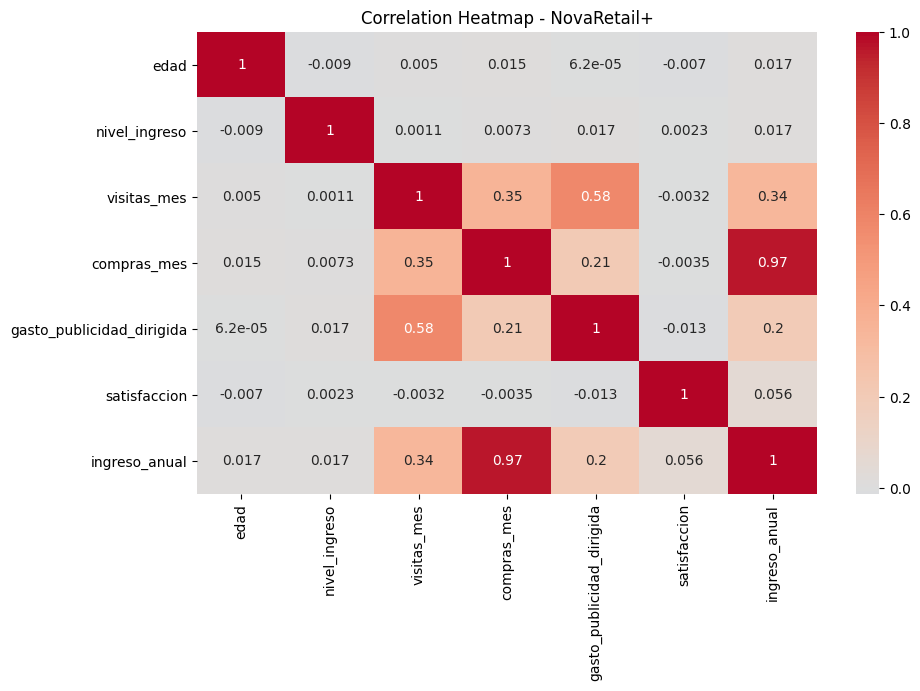

In [14]:
# Visualizar la matriz de correlación para identificar relaciones
df_corr = df[["edad", "nivel_ingreso", "visitas_mes", "compras_mes", "gasto_publicidad_dirigida", "satisfaccion", "ingreso_anual"]].corr()
plt.figure(figsize=(10, 6))
sns.heatmap(df_corr, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap - NovaRetail+")
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves


Observaciones generales (Heatmap)  
- La edad, el nivel de ingreso e incluso la satisfacción son las categorías que menos tienen correlación respecto a otras columnas, por ejemplo el heatmap muestra un valor de 6.2e-05 en la intersección de edad con gasto en publicidad dirigida que equivale a 0.000062, lo que significa que la correlación que tienen ambas variables es prácticamente nula.
  
- Las visitas al mes con ingreso anual y compras al mes tienen una correlación débil positiva con 0.34 y 0.35, y las visitas al mes con gasto en publicidad dirigida tienen una correlación moderada positiva con 0.58. Las compras al mes con gasto en publicidad dirigida y visitas al mes presentan una correlación débil positiva con 0.21 y 0.35, y compras al mes con ingreso anual tienen una correlación fuerte positiva de 0.97 (posible colinealidad). El gasto en publicidad dirigida e ingreso anual tienen una correlación débil positiva con 0.2. Respecto al ingreso anual con satisfacción tiene una correlación muy débil positiva de 0.056.


Observaciones respecto a `ingreso_anual`  
- En las intersecciones de ingreso anual con la edad y el nivel de ingreso presentan una correlación prácticamente nula de 0.017 en ambas, y un 0.056 correlacionada con satisfacción, por lo que se deduce que ninguna de estas variables influye al ingreso anual de la empresa.
  
- Así mismo, presenta correlaciones débiles positivas con gasto en publicidad dirigida con 0.2 y con visitas al mes con 0.34, por lo que se recomendaría seguir monitoreando estas variables con el objetivo de conocer si realmente influyen aunque sea en poca cantidad como se muestra en el heatmap.

- Por último hay una correlación fuerte positiva con compras al mes con 0.97, lo que puede indicar una posibilidad de colinealidad. Aunque teóricamente esto es verdad, considero que ambas variables pueden brindar información muy útil dependiendo el caso porque las compras al mes que hace cada cliente hablan de su comportamiento como consumidor, pero el ingreso anual que genera cada uno también es impresindible al momento de querer conocer los ingresos anuales totales al final del periodo de la empresa.


#Resumen de hallazgos
- Colinealidad fuerte: compras_mes e ingreso_anual (0.97) — casi se mueven idénticamente.
- Correlación moderada: visitas_mes y gasto_publicidad (0.58).
- Correlaciones débiles: varias combinaciones entre 0.2 y 0.35.
- Correlaciones nulas o casi nulas: edad con casi todo, e ingreso_anual con satisfaccion.

### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.
  - Considero que no es necesario realizar un scatterplot general debido a que con la visualización del heatmap es suficiente para detectar las variables que vale la pena analizar más a fondo como visitas y gasto en publicidad dirigida que son las que tienen una correlación moderada. Además, de que debido al tamaño del dataset con las 15,000 filas sería un poco complicada la visualización de todos los puntos distribuidos únicamente en las 7 variables numéricas. Por otra parte, debido a que ya se identificaron que hay variables como edad, nivel de ingreso y satisfacción que presentan correlaciones casi nulas la realización de un scatterplot no revelaría información relevante.

### Scatterplot para pares clave

<AxesSubplot:xlabel='compras_mes', ylabel='ingreso_anual'>

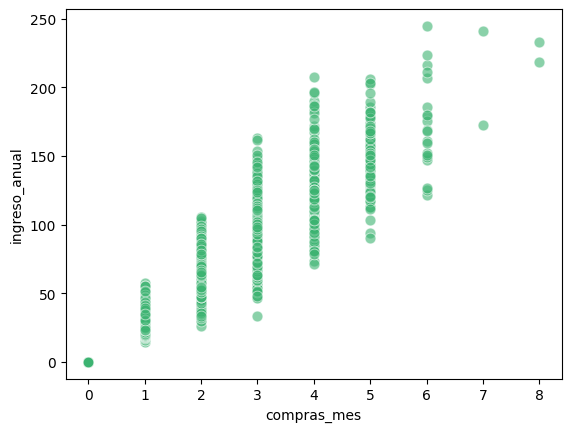

In [15]:
# Visualizar pares de variables con relaciones moderadas o fuertes
#Colinealidad fuerte: compras_mes e ingreso_anual (0.97)
sns.scatterplot(data=df, x="compras_mes", y="ingreso_anual",
    color="mediumseagreen", 
    alpha=0.6,
    s=60
    ) 

<AxesSubplot:xlabel='visitas_mes', ylabel='gasto_publicidad_dirigida'>

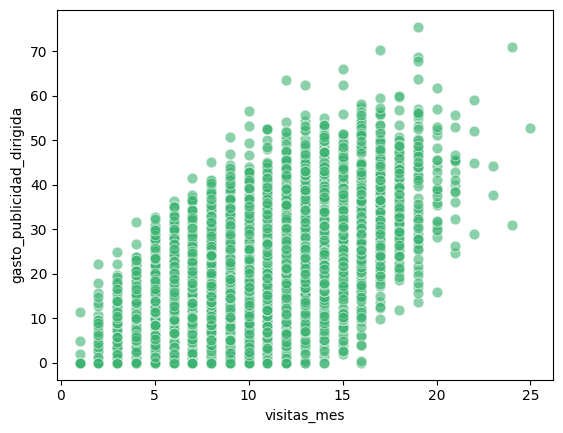

In [16]:
#Correlación moderada: visitas_mes y gasto_publicidad_dirigida (0.58)
sns.scatterplot(data=df, x="visitas_mes", y="gasto_publicidad_dirigida",
    color="mediumseagreen", 
    alpha=0.6,
    s=60
    )

<AxesSubplot:xlabel='edad', ylabel='gasto_publicidad_dirigida'>

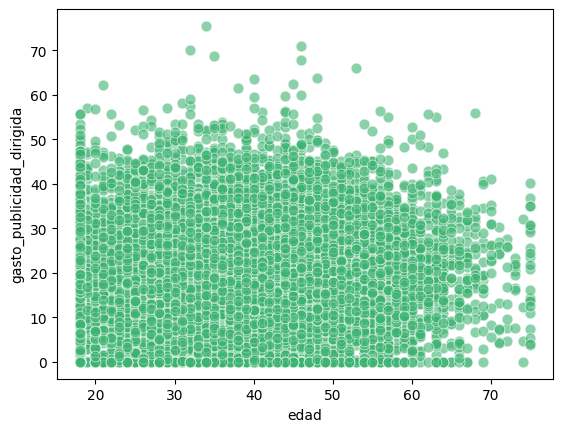

In [17]:
#Correlación débil: edad y gasto en publicidad dirigida (0.000062)
sns.scatterplot(data=df, x="edad", y="gasto_publicidad_dirigida",
    color="mediumseagreen", 
    alpha=0.6,
    s=60
    )

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)

**Colinealidad fuerte: compras_mes vs ingreso_anual(0.97)**
- Comparando el scatterplot de las variables compras_mes e ingreso_anual puede afirmarse que tiene una dirección positiva con dispersión baja de 1 a 5 compras por mes, pero los puntos tienden a separase un poco cuando llega a 6. A simple vista parecen posibles outliers que corresponden a las cantidades de 0, 7 y 8, pero que si analizamos el contexto no se consideran anómalos, pueden ser aún en este caso valores normales, porque puede existir un registro de 0 compras que generen $0 ingresos anuales, pero también que exista la posibilidad de 7 u 8 compras con valores en ingresos anuales similares a los de 6 si son productos con un costo unitario menor.  Así mismo, presenta probabilidad de colinealidad.


**Correlación moderada: visitas_mes y gasto_publicidad_dirigida (0.58)**
- Respecto al scatterplot de visitas_mes y gasto_publicidad puede decirse que tiene una dirección positiva con dispersión media, donde los puntos tienden a separse más cuando llegan a la cantidad de 20 visitas por mes. Al observar por primera vez el scatterplot podemos deducir que hay outliers en las cantidades de 1, 22, 23, 24 y 25 visitas al mes, sin embargo por el análisis anterior sabemos que puede ser posible que existan esta cantidad de visitas en usuarios que sean más activos durante más días o que acostumbren visitar el sitio varias veces al día, por lo que pueden tomarse como valores normales. En este caso hay posible colinealidad, pero no es tan fuerte para considerarla un problema, ya que el valor es de 0.58 que entra dentro del rango moderado, por lo que se podrían mantener ambas variables, pero teniendo cuidado al momento de realizar cualquier análisis.


**Correlación débil: edad y gasto en publicidad dirigida (0.000062)**
- En este caso las variables edad y gasto en publicidad dirigida tienen una dirección ligeramente negativa en las edades de 30 a 70, de igual modo el scatterplot presenta dispersión alta. Así mismo, a simple vista podemos ver presencia de outliers en las edades de 75 y 76, sin embargo se sabe que son edades razonables, por lo que entran dentro de los valores normales. En este caso no hay riesgo de colinealidad, ya que se tiene una cantidad muy baja de correlación de 0.000062, lo significa que no existe una relación lineal entre las variables que permita predecir el comportamiento de una a partir de la otra

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a>
<b>Atención ⚠️</b><br>
Las observaciones del heatmap y de los tres scatterplots son muy completas, con un análisis particularmente cuidadoso sobre valores que a primera vista parecen outliers pero que resultan ser razonables al considerar el contexto de negocio. Un punto a completar para tu portafolio: la celda de código del scatterplot general quedó vacía, sin gráfico ni justificación escrita (ver recomendación extendida en el Review General). Como nota de terminología: usas "colinealidad" de forma consistente a lo largo del proyecto para describir la fuerza de las correlaciones (por ejemplo, como título de sección: "Colinealidad fuerte: compras_mes e ingreso_anual"). Técnicamente, ese término corresponde a un problema entre variables predictoras en un modelo de regresión, no es el nombre de una correlación fuerte en un análisis descriptivo — puedes reemplazarlo por "correlación fuerte" en estos títulos y observaciones (aunque, como verás en mi comentario de la Sección 5, el uso que le das en el Hallazgo 2 sí es conceptualmente correcto).
</div>

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [18]:
# Calcular correlación entre variables relevantes 
#Colinealidad fuerte: compras_mes vs ingreso_anual(0.97)
print(df['compras_mes'].corr(df['ingreso_anual'], method='pearson'))
print(df['compras_mes'].corr(df['ingreso_anual'], method='spearman'))

0.9671485435708564
0.967482492032673


Cuando Pearson y Spearman coinciden tan de cerca, significa que la relación no solo es fuerte, sino que es consistentemente lineal, es decir, no hay curvas raras ni valores atípicos que estén distorsionando la relación de forma diferente para cada método.

In [19]:
# Calcular correlación entre variables relevantes
#Correlación moderada: visitas_mes y gasto_publicidad_dirigida (0.58)
print(df['visitas_mes'].corr(df['gasto_publicidad_dirigida'], method='pearson'))
print(df['visitas_mes'].corr(df['gasto_publicidad_dirigida'], method='spearman'))

0.5789472719412827
0.5592673242622609


- En este caso hay más outliers, por lo que la correlacion es un poco menos lineal y ligeramente menos consistente.
  
- Pearson, al basarse en los valores reales (medias y desviaciones), es sensible a valores extremos que pueden "estirar" la relación lineal aparente.

- Spearman, al trabajar con rangos (posiciones ordenadas) en lugar de valores absolutos, no se deja influenciar tanto por esos outliers, por lo que refleja mejor la tendencia general monotónica de los datos.

- El hecho de que Pearson (0.579) sea mayor que Spearman (0.559) sugiere que hay algunos valores atípicos que están "ayudando" a inflar ligeramente la correlación lineal, aunque la diferencia no es enorme.

In [20]:
# Calcular correlación entre variables relevantes
#Correlación débil: edad y gasto en publicidad dirigida (0.000062)
print(df['edad'].corr(df['gasto_publicidad_dirigida'], method='pearson'))
print(df['edad'].corr(df['gasto_publicidad_dirigida'], method='spearman'))

6.218953734477077e-05
0.0028693239157135363


- Aunque presentan cantidades que varian un poco a partir del tercer decimal, prácticamente el resultado es cero.
- Un coeficiente cercano a 0 (ya sea Pearson o Spearman) indica ausencia de relación lineal/monótona entre las variables.
- En este caso, la edad del cliente no influye en cuánto gasto en publicidad dirigida recibe.
- No existe una relación entre cómo varía la edad y cómo varía el gasto en publicidad.

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

**Colinealidad fuerte: compras_mes vs ingreso_anual(0.97)**
- Al comparar las variables compras por mes e ingreso anual, se aprecia que su dirección es positiva y de magnitud fuerte. Al ser un valor alto de 0.97 tanto en el coeficiente de Person como en el de Spearman redondeados, puede existir riesgo de colinealidad.

**Correlación moderada: visitas_mes y gasto_publicidad_dirigida (0.58)**
- Analizando las variables visitas por mes y gasto en publicidad dirigidad, se distingue que su dirección sigue siendo positiva, pero es menos fuerte respecto a su magnitud. Al ser 0.58 (Pearson) y 0.56 (Spearman) valores que entra dentro de los rango de "moderado" existe un riesgo de colinealidad baja. 

**Correlación débil: edad y gasto_publicidad_dirigida (0.000062)**
- En este caso las variables edad y gasto en publicidad dirigida tienen una dirección ligeramente negativa con una magnitud débil. Al ser 0.000062 (Pearson) y 0.0028 (Spearman) valores que entran dentro del rango de correlación nula o muy débil, no hay riesgo de colinealidad.

### Punto-biserial

In [21]:
# Calcular correlación entre variables relevantes
#miembro_premium vs ingreso_anual
punto_biserial1= pointbiserialr(df["miembro_premium"], df["ingreso_anual"])
print(punto_biserial1)

SignificanceResult(statistic=0.0930994396198015, pvalue=3.0943076155242597e-30)


In [22]:
#abandono vs ingreso_anual
punto_biserial2= pointbiserialr(df["abandono"], df["ingreso_anual"])
print(punto_biserial2)

SignificanceResult(statistic=-0.002823934021617148, pvalue=0.7294691719078393)


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**miembro_premium vs ingreso_anual**
- El coeficiente de correlación punto-biserial entre "ser miembro premium" y el "ingreso anual que recibe la empresa de cada cliente" es de 0.093, lo que indica que la dirección es positiva, y esto significa que cuando la variable binaria pasa de 0 a 1 (en este caso, de "no premium" a "premium"), el ingreso anual tiende a aumentar. Respecto a su magnitud (0.093) al ser muy cercana a 0 tiene una relación débil.

- El pvalue que en este caso es de 3.0943076155242597e-30 o 0.00000000000000000000000000000309, al ser menor que 0.05 significa que la correlación de 0.093 no es producto del azar, por lo que es prudente confiar en este resultado, pero no en el resultado del punto biserial ya que como se mencionó antes 0.093 representa una correlación muy débil.


**abandono vs ingreso anual**
- El coeficiente punto-biserial entre las variables abandono e ingreso anual es de -0.0028, lo que señala que tiene una dirección negativa y una magnitud débil, ya que es un número muy cercano a 0.

- Respecto al pvalue, en esta ocasión es de 0.7294, si no existiera ninguna relación real entre abandono e ingreso anual, hay un 72.94% de probabilidad de obtener un coeficiente como -0.0028 (o más extremo) solo por azar muestral.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a>
<b>Éxito ✅</b><br>
Excelente análisis de coeficientes. Pearson y Spearman se calculan y comparan correctamente para tres pares, con interpretación precisa de por qué valores más dispares entre ambos (como en <code>visitas_mes vs gasto_publicidad_dirigida</code>) sugieren menor linealidad. El Punto-biserial distingue con rigor entre significancia estadística y magnitud práctica, citando el p-value con notación científica completa. La V de Cramér está correctamente interpretada.
</div>

### V de Cramér

In [23]:
# Función para calcular V de Cramér
tabla= pd.crosstab(df["region"], df["tipo_dispositivo"])
tabla

tipo_dispositivo,escritorio,móvil,tablet
region,,,
este,766,2003,300
norte,1125,2843,427
oeste,935,2489,386
sur,894,2483,349


In [24]:
#chi-cuadrado
chi2, p, dof, expected = chi2_contingency(tabla)
chi2

4.596697852095489

In [30]:
# Aplicar V de Cramér en variables relevantes
#Conteos tabla
n= tabla.sum(). sum()

#Usar el valor chi-cuadrado
cramers_v= np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
cramers_v

0.012378338407739397

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves

Observaciones V de Cramér
- El valor V de Cramér tiene un coeficiente de 0.0123, el cual recae en la escala de relación muy débil o inexistente. Este resultado indica que las variables region y tipo de dispositivo son prácticamente independientes.

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️ **Hallazgos**: Completa los siguientes bloques.   
Si lo crees necesario, puedes agregar mas hallazgos.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### Hallazgo 1 — Región y tipo de dispositivo
  
**Evidencia numérica:** 
V de Cramér = 0.0123

**Interpretación**  
Ninguno de los tipos de dispositivos, ya sea móvil, tablet o escritorio, que utilizan los clientes prevalece en ninguna de las regiones presentadas (norte, sur, este, oeste).

**No podemos afirmar**  
Que una región tenga preferencia por usar un dispositivo u otro.

**Implicación de negocio**  
No se recomienda realizar campañas enfocadas a cada región según el tipo de dispositivo que usan, ya que no son variables que tengan relación.

### Hallazgo 2 — Compras_mes e ingreso_anual

**Evidencia visual:**  
Heatmap y Scatterplot 

**Evidencia numérica:** 
Pearson: 0.9671 
Spearman: 0.9674

**Interpretación**  
Los clientes que realizan más compras al mes tienden a estar asociados con un ingreso anual mayor a la empresa.

**No podemos afirmar**  
Que no exista colinealidad entre las variables compras por mes e ingreso anual, ya que es probable que el ingreso anual se calcule apartir del número de compras que realizan los clientes.

**Implicación de negocio**  
Se recomienda analizar otras variables que impulsen el crecimiento del ingreso anual, ya que esta asociación no aporta información accionable al ser prácticamente la misma variable.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a>
<b>Éxito ✅</b><br>
Ambos hallazgos son excelentes. El Hallazgo 2 destaca especialmente: cuestionas con madurez analítica si la correlación de 0.97 entre <code>compras_mes</code> e <code>ingreso_anual</code> refleja un comportamiento genuino o una superposición en cómo se calculan ambas variables — y aquí el término "colinealidad" sí se usa en su sentido correcto (variables que podrían estar midiendo esencialmente lo mismo). La implicación de negocio, enfocarse en otras variables que sí aporten información accionable, es acertada y bien fundamentada.
</div>

## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**: Completa el siguiente bloque.   
Modifica según creas necesario.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### **Limitaciones**
- Correlación ≠ causalidad: Los cálculos solo brindan información acerca de la existencia de asociación entre las variables, no prueban que una variable cause cambio en la otra.
- Posible colinealidad por variables que se calculan a partir de otras.
- Falta de información en el dataset como tiempo del cliente en la plataforma, categoría de productos comprados, razones de los clientes para eligir cierto dispositivo para ingresar a la página, etc.

### **Próximos pasos** 

Probar segmentación adicional
- Entre clientes con más y menos visitas para analizar como se comporta la relación entre las variables gasto dirigido y visitas por mes en cada uno de los grupos.
- Entre clientes premium y no premium para analizar si existe alguna diferencia significativa entre compras al mes y tener la posibilidad de crear campañas dirigidas para motivar aún más las compras.

Recabar información adicional de los clientes
- Tiempo en la plataforma: porque ayuda detectar problemas de navegación.
- Categoría/productos específicos: debido a que permite la creación de campañas dirigidas.
- Razón de uso del dispositivo: ayuda a detectar si el diseño responsivo tiene problemas en alguno de los dispositivos.

Probar un test A/B
- Donde a un grupo de clientes se le muestre más publicidad y a otro no para medir si realmente tiene un impacto en las visitas o compras.
- Donde a un grupo de clientes NO premium se le dé por tiempo limitado, un mes por ejemplo, algún beneficio que tengan los clientes premium (supongamos que entregas sin costo) con el objetivo de analizar si este cambio aumenta la cantidad de miembros premium.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a>
<b>Éxito ✅</b><br>
Sección de cierre muy sólida. Las limitaciones conectan directamente con el Hallazgo 2 (posible colinealidad por variables derivadas entre sí). Los próximos pasos están organizados en tres ejes bien diseñados, incluyendo dos propuestas concretas de test A/B con hipótesis claras.
</div>